In [2]:

!pip install -q tensorflow-datasets scikit-image opencv-python-headless


In [3]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import tensorflow_datasets as tfds

from skimage.feature import hog, graycomatrix, graycoprops

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [5]:

project_path = "/content/drive/MyDrive/Crop_Disease_Project"

os.makedirs(project_path, exist_ok=True)

print("Project folder created successfully!")


Project folder created successfully!


In [9]:
!pip install -q importlib-resources

In [1]:
import tensorflow_datasets as tfds

data_dir = "/content/drive/MyDrive/PlantVillage_Data"
builder = tfds.builder("plant_village", data_dir=data_dir)

builder.download_and_prepare()

print("Dataset downloaded successfully!")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/drive/MyDrive/PlantVillage_Data/plant_village/incomplete.G93J3R_1.0.2/plant_village-train.t…

Dataset plant_village downloaded and prepared to /content/drive/MyDrive/PlantVillage_Data/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset downloaded successfully!


In [2]:
class_names = builder.info.features["label"].names

selected_classes = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Bacterial_spot",
    "Tomato___Leaf_Mold"
]

selected_ids = {
    name: class_names.index(name)
    for name in selected_classes
}

print("Selected classes:")
for name, label_id in selected_ids.items():
    print(name, ":", label_id)

Selected classes:
Tomato___healthy : 30
Tomato___Early_blight : 29
Tomato___Late_blight : 31
Tomato___Bacterial_spot : 28
Tomato___Leaf_Mold : 32


In [3]:
import cv2
import numpy as np
from collections import Counter

dataset = builder.as_dataset(
    split="train",
    shuffle_files=False
)

max_images_per_class = 500

images = []
labels = []

class_counts = Counter()

for example in dataset:

    label_id = int(example["label"].numpy())

    if label_id not in selected_ids.values():
        continue

    if class_counts[label_id] >= max_images_per_class:
        continue

    image = example["image"].numpy()

    image = cv2.resize(image, (128, 128))

    images.append(image)
    labels.append(label_id)

    class_counts[label_id] += 1

    if all(
        class_counts[x] >= max_images_per_class
        for x in selected_ids.values()
    ):
        break

X_images = np.array(images, dtype=np.uint8)
y_labels = np.array(labels)

print("Image extraction completed!")
print("Image shape:", X_images.shape)
print("Labels shape:", y_labels.shape)
print("Total images:", len(X_images))

Image extraction completed!
Image shape: (2500, 128, 128, 3)
Labels shape: (2500,)
Total images: 2500


In [4]:
for name, label_id in selected_ids.items():
    count = np.sum(y_labels == label_id)
    print(name, ":", count)

Tomato___healthy : 500
Tomato___Early_blight : 500
Tomato___Late_blight : 500
Tomato___Bacterial_spot : 500
Tomato___Leaf_Mold : 500


In [7]:
import matplotlib.pyplot as plt

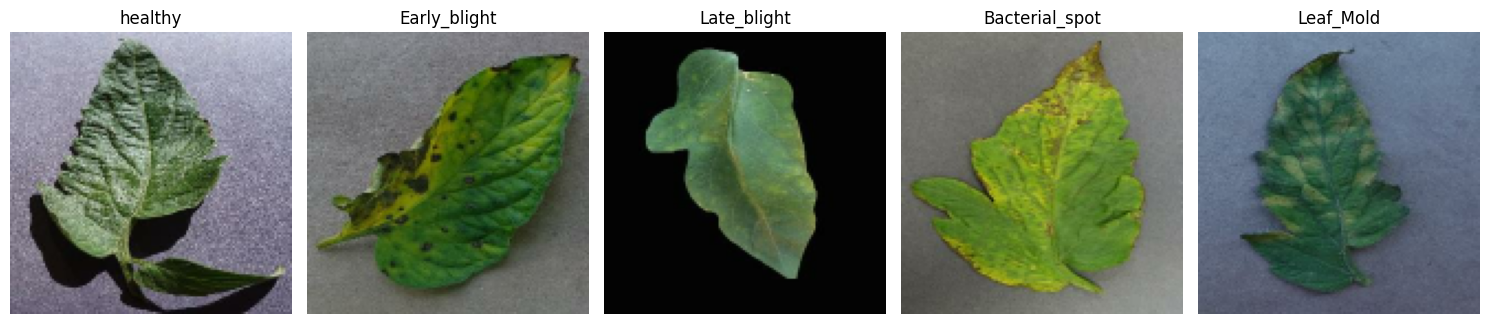

In [8]:
plt.figure(figsize=(15, 6))

for i, (name, label_id) in enumerate(selected_ids.items()):

    index = np.where(y_labels == label_id)[0][0]

    plt.subplot(1, 5, i + 1)
    plt.imshow(X_images[index])
    plt.title(name.replace("Tomato___", ""))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
print("Total images:", len(X_images))
print("Image dimensions:", X_images.shape)
print("Label dimensions:", y_labels.shape)
print("Number of classes:", len(selected_ids))

Total images: 2500
Image dimensions: (2500, 128, 128, 3)
Label dimensions: (2500,)
Number of classes: 5


In [11]:
import pandas as pd

In [12]:
class_data = []

for name, label_id in selected_ids.items():

    count = np.sum(y_labels == label_id)

    class_data.append({
        "Disease": name.replace("Tomato___", ""),
        "Image Count": count
    })

df = pd.DataFrame(class_data)

print(df)

          Disease  Image Count
0         healthy          500
1    Early_blight          500
2     Late_blight          500
3  Bacterial_spot          500
4       Leaf_Mold          500


In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

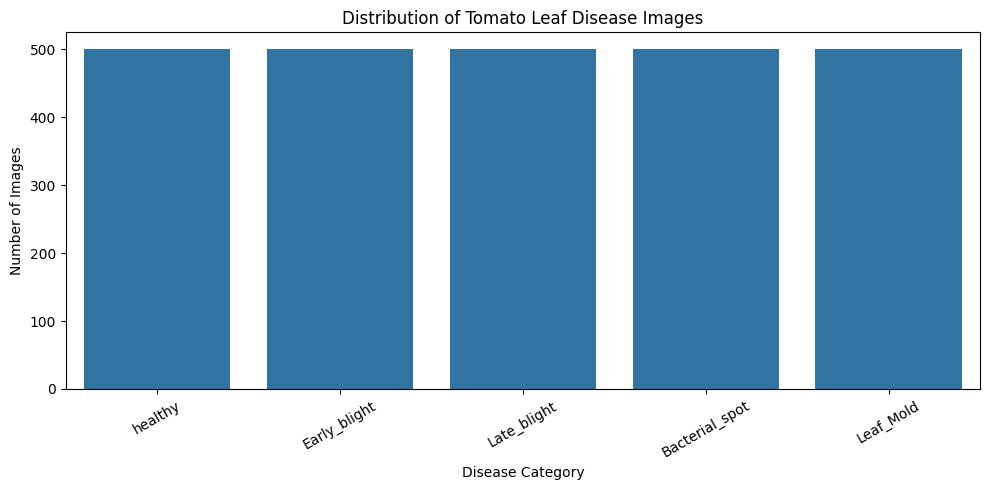

In [14]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Disease",
    y="Image Count"
)

plt.title("Distribution of Tomato Leaf Disease Images")
plt.xlabel("Disease Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

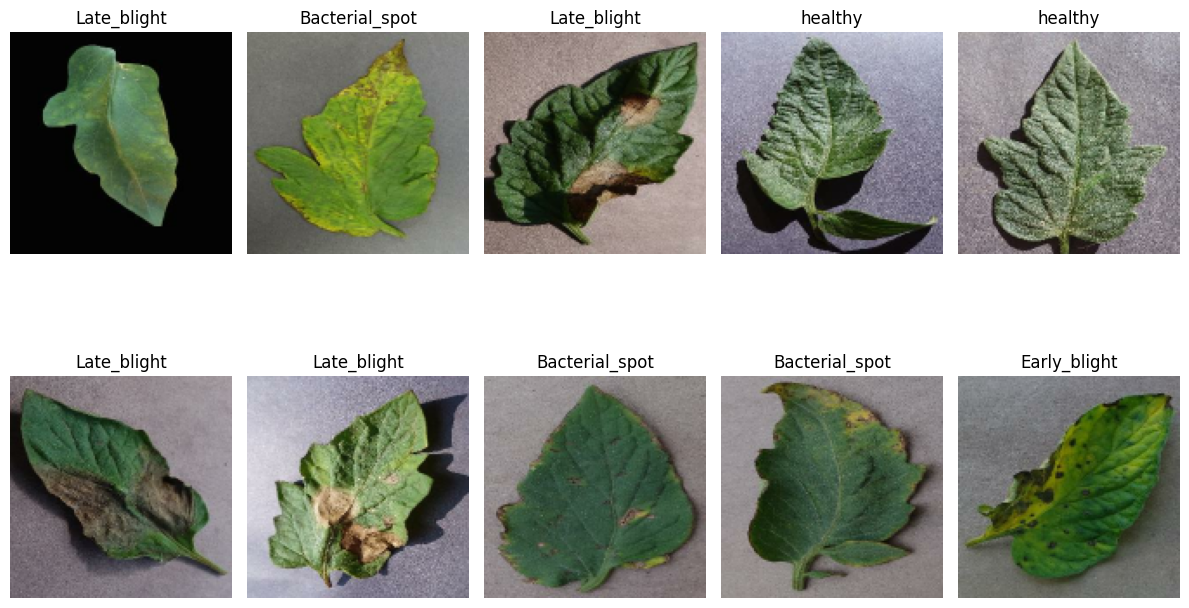

In [15]:
plt.figure(figsize=(12, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_images[i])

    label_name = [
        name.replace("Tomato___", "")
        for name, label_id in selected_ids.items()
        if label_id == y_labels[i]
    ][0]

    plt.title(label_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
print("Total images:", len(X_images))

print("Image dimensions:", X_images.shape)

print("Label dimensions:", y_labels.shape)

print("Image data type:", X_images.dtype)

print("Label data type:", y_labels.dtype)

print("Minimum pixel value:", X_images.min())

print("Maximum pixel value:", X_images.max())

print("Dataset size in MB:",
      X_images.nbytes / (1024 * 1024))

Total images: 2500
Image dimensions: (2500, 128, 128, 3)
Label dimensions: (2500,)
Image data type: uint8
Label data type: int64
Minimum pixel value: 0
Maximum pixel value: 255
Dataset size in MB: 117.1875


In [18]:
import os

project_path = "/content/drive/MyDrive/Crop_Disease_Project"

os.makedirs(project_path, exist_ok=True)

print("Project folder is ready!")

Project folder is ready!


In [19]:
 np.savez_compressed(
    project_path + "/tomato_dataset.npz",
    images=X_images,
    labels=y_labels
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [20]:
import os

file_path = project_path + "/tomato_dataset.npz"

print("File exists:", os.path.exists(file_path))
print("File size (MB):", round(os.path.getsize(file_path) / (1024 * 1024), 2))

File exists: True
File size (MB): 82.65


In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import hog, graycomatrix, graycoprops

print("Feature extraction libraries imported successfully!")

Feature extraction libraries imported successfully!


In [22]:
def extract_features(image):

    # 1. COLOR HISTOGRAM
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    color_features = []

    for channel in range(3):
        hist = cv2.calcHist(
            [hsv], [channel], None, [16],
            [0, 180] if channel == 0 else [0, 256]
        )

        hist = cv2.normalize(hist, hist).flatten()
        color_features.extend(hist)

    # 2. HOG FEATURES
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    hog_features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    # 3. GLCM TEXTURE FEATURES
    # Reduce grayscale levels to 8 for efficient computation
    gray_quantized = (gray // 32).astype(np.uint8)

    glcm = graycomatrix(
        gray_quantized,
        distances=[1, 3],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=8,
        symmetric=True,
        normed=True
    )

    texture_features = []

    properties = [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation"
    ]

    for prop in properties:
        values = graycoprops(glcm, prop).flatten()
        texture_features.extend(values)

    # Combine all features
    combined_features = np.concatenate([
        color_features,
        hog_features,
        texture_features
    ])

    return np.nan_to_num(combined_features)

In [23]:
sample_features = extract_features(X_images[0])

print("Feature extraction successful!")
print("Number of extracted features:", len(sample_features))
print("Feature vector shape:", sample_features.shape)
print("First 10 features:", sample_features[:10])

Feature extraction successful!
Number of extracted features: 1852
Feature vector shape: (1852,)
First 10 features: [0.9550879  0.0022192  0.01266793 0.07933637 0.21526234 0.18410107
 0.02995919 0.0024966  0.0022192  0.002774  ]


In [24]:
import time

feature_list = []

start_time = time.time()

for i, image in enumerate(X_images):

    features = extract_features(image)
    feature_list.append(features)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(X_images)} images")

X_features = np.array(feature_list, dtype=np.float32)

print("\nFeature extraction completed!")
print("Feature matrix shape:", X_features.shape)
print("Total images processed:", len(X_features))
print("Total features per image:", X_features.shape[1])
print("Time taken:", round(time.time() - start_time, 2), "seconds")

Processed 100/2500 images
Processed 200/2500 images
Processed 300/2500 images
Processed 400/2500 images
Processed 500/2500 images
Processed 600/2500 images
Processed 700/2500 images
Processed 800/2500 images
Processed 900/2500 images
Processed 1000/2500 images
Processed 1100/2500 images
Processed 1200/2500 images
Processed 1300/2500 images
Processed 1400/2500 images
Processed 1500/2500 images
Processed 1600/2500 images
Processed 1700/2500 images
Processed 1800/2500 images
Processed 1900/2500 images
Processed 2000/2500 images
Processed 2100/2500 images
Processed 2200/2500 images
Processed 2300/2500 images
Processed 2400/2500 images
Processed 2500/2500 images

Feature extraction completed!
Feature matrix shape: (2500, 1852)
Total images processed: 2500
Total features per image: 1852
Time taken: 15.1 seconds


In [25]:
np.savez_compressed(
    project_path + "/tomato_features.npz",
    features=X_features,
    labels=y_labels
)

print("Feature dataset saved successfully!")

Feature dataset saved successfully!


In [26]:
print("Feature matrix:", X_features.shape)
print("Labels:", y_labels.shape)
print("Feature data type:", X_features.dtype)
print("Contains invalid values:", np.isnan(X_features).any())

Feature matrix: (2500, 1852)
Labels: (2500,)
Feature data type: float32
Contains invalid values: False


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_features,
    y_labels,
    test_size=0.20,
    random_state=42,
    stratify=y_labels
)

print("Data splitting completed!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Data splitting completed!
Training features: (2000, 1852)
Testing features: (500, 1852)
Training labels: (2000,)
Testing labels: (500,)


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

print("Model libraries imported successfully!")

Model libraries imported successfully!


In [29]:
# 1. Support Vector Machine
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=10,
        gamma="scale"
    ))
])

# 2. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# 3. K-Nearest Neighbors
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ))
])

print("All three models created successfully!")

All three models created successfully!


In [30]:
print("SVM:", svm_model)
print("\nRandom Forest:", rf_model)
print("\nKNN:", knn_model)

SVM: Pipeline(steps=[('scaler', StandardScaler()), ('classifier', SVC(C=10))])

Random Forest: RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

KNN: Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier(weights='distance'))])


In [31]:
import time

start = time.time()

svm_model.fit(X_train, y_train)

svm_train_time = time.time() - start

print("SVM training completed!")
print("Training time:", round(svm_train_time, 2), "seconds")


SVM training completed!
Training time: 5.26 seconds


In [32]:
start = time.time()

rf_model.fit(X_train, y_train)

rf_train_time = time.time() - start

print("Random Forest training completed!")
print("Training time:", round(rf_train_time, 2), "seconds")

Random Forest training completed!
Training time: 18.82 seconds


In [33]:
start = time.time()

knn_model.fit(X_train, y_train)

knn_train_time = time.time() - start

print("KNN training completed!")
print("Training time:", round(knn_train_time, 2), "seconds")

KNN training completed!
Training time: 0.07 seconds


In [34]:
print("ALL MODELS TRAINED SUCCESSFULLY!")
print("--------------------------------")
print("SVM time:", round(svm_train_time, 2), "seconds")
print("Random Forest time:", round(rf_train_time, 2), "seconds")
print("KNN time:", round(knn_train_time, 2), "seconds")

ALL MODELS TRAINED SUCCESSFULLY!
--------------------------------
SVM time: 5.26 seconds
Random Forest time: 18.82 seconds
KNN time: 0.07 seconds


In [35]:
svm_predictions = svm_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)
knn_predictions = knn_model.predict(X_test)

print("Predictions completed for all three models!")

Predictions completed for all three models!


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

models = {
    "SVM": svm_predictions,
    "Random Forest": rf_predictions,
    "KNN": knn_predictions
}

results = []

for model_name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, predictions, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, average="macro", zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", model_name)
    print(classification_report(
        y_test,
        predictions,
        labels=sorted(selected_ids.values()),
        target_names=selected_classes,
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))


 SVM
                         precision    recall  f1-score   support

       Tomato___healthy       0.95      0.94      0.94       100
  Tomato___Early_blight       0.77      0.79      0.78       100
   Tomato___Late_blight       1.00      0.99      0.99       100
Tomato___Bacterial_spot       0.83      0.78      0.80       100
     Tomato___Leaf_Mold       0.86      0.91      0.88       100

               accuracy                           0.88       500
              macro avg       0.88      0.88      0.88       500
           weighted avg       0.88      0.88      0.88       500


 Random Forest
                         precision    recall  f1-score   support

       Tomato___healthy       0.91      0.95      0.93       100
  Tomato___Early_blight       0.79      0.82      0.80       100
   Tomato___Late_blight       1.00      1.00      1.00       100
Tomato___Bacterial_spot       0.91      0.80      0.85       100
     Tomato___Leaf_Mold       0.91      0.95      0.93       100

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.882,0.8825,0.882,0.8819
1,Random Forest,0.904,0.9049,0.904,0.9035
2,KNN,0.666,0.7094,0.666,0.6344


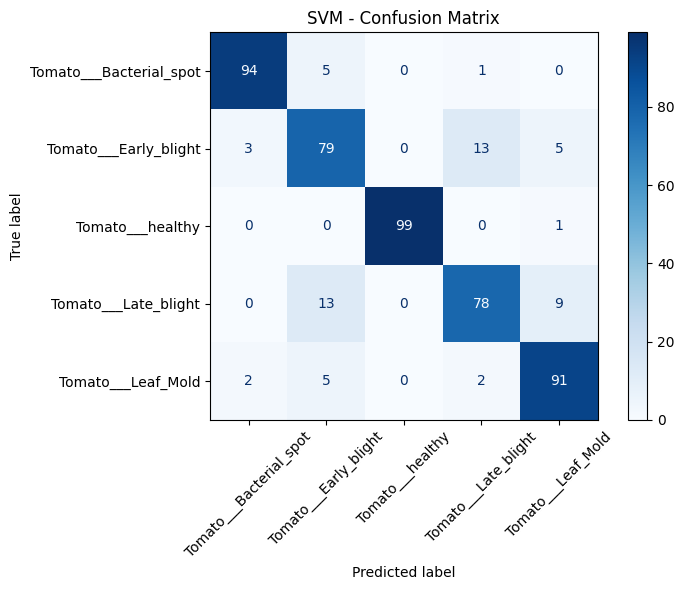

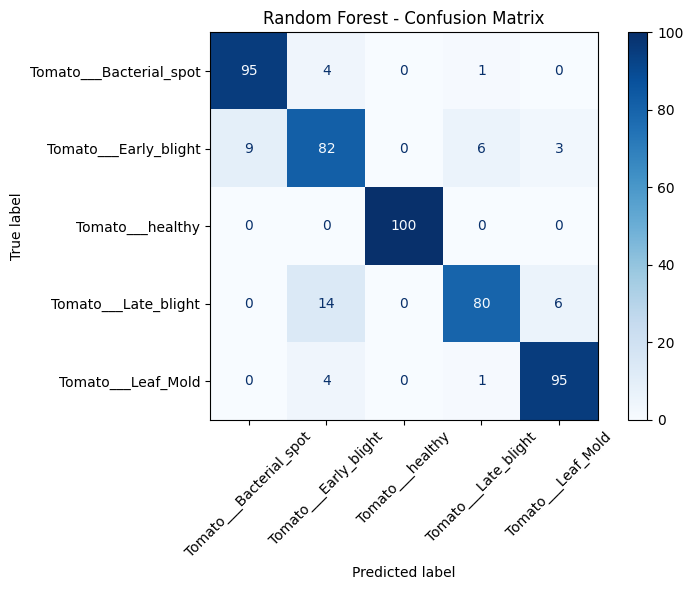

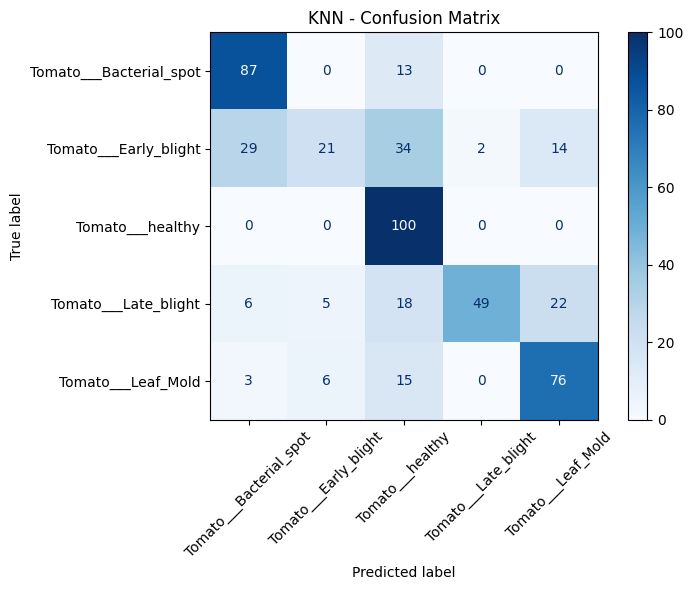

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Keep class names in the same order as their numeric label IDs
ordered_ids = sorted(selected_ids.values())
ordered_names = [class_names[i] for i in ordered_ids]

predictions_dict = {
    "SVM": svm_predictions,
    "Random Forest": rf_predictions,
    "KNN": knn_predictions
}

for model_name, predictions in predictions_dict.items():

    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=ordered_ids,
        display_labels=ordered_names,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d",
        ax=ax
    )

    ax.set_title(model_name + " - Confusion Matrix")
    plt.tight_layout()
    plt.show()

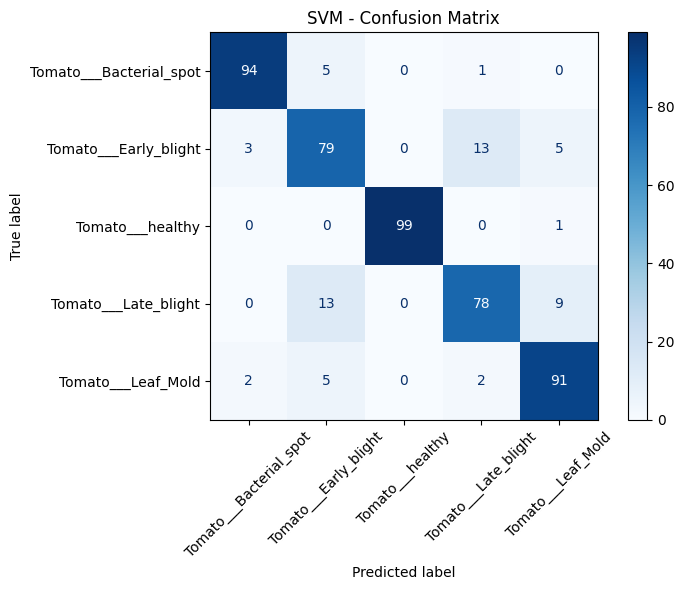

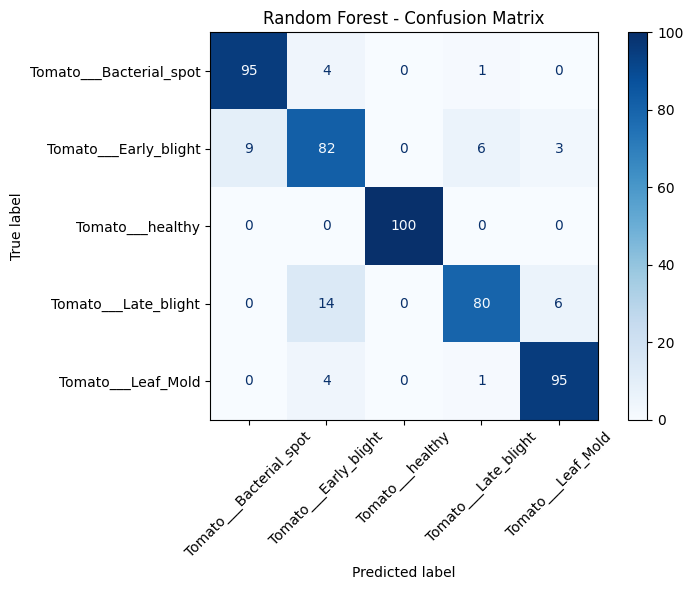

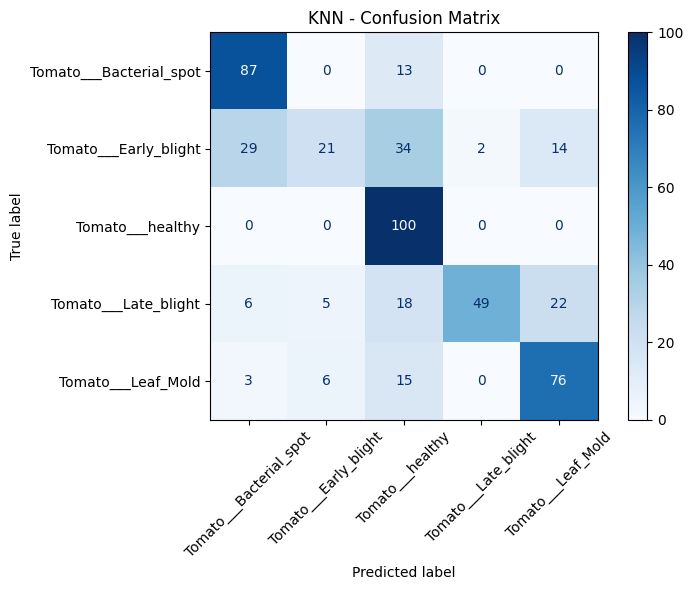

All confusion matrices saved successfully!


In [38]:
from sklearn.metrics import confusion_matrix
import os

for model_name, predictions in predictions_dict.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=ordered_ids
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=ordered_names
    )

    disp.plot(
        cmap="Blues",
        xticks_rotation=45,
        values_format="d",
        ax=ax
    )

    ax.set_title(model_name + " - Confusion Matrix")
    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_") + "_confusion_matrix.png"
    plt.savefig(os.path.join(project_path, filename), dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("All confusion matrices saved successfully!")

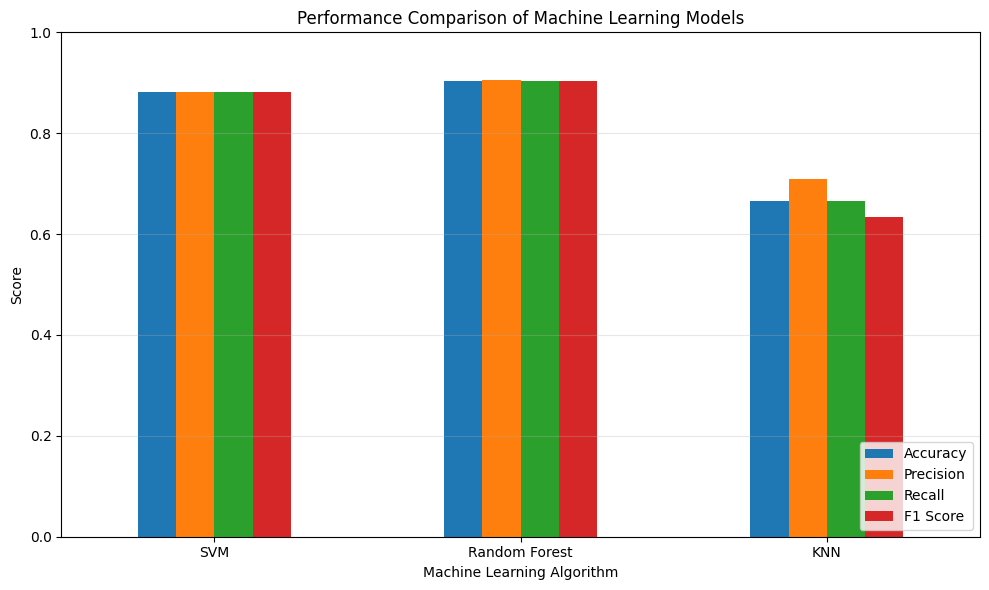

Model comparison graph saved successfully!


In [39]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Algorithm")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    project_path + "/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison graph saved successfully!")

In [40]:
import joblib
import os

joblib.dump(svm_model, project_path + "/svm_model.pkl")
joblib.dump(rf_model, project_path + "/random_forest_model.pkl")
joblib.dump(knn_model, project_path + "/knn_model.pkl")

print("All three trained models saved successfully!")

All three trained models saved successfully!


In [41]:
print("Saved project files:")

for filename in os.listdir(project_path):
    print(filename)

Saved project files:
tomato_dataset.npz
tomato_features.npz
svm_confusion_matrix.png
random_forest_confusion_matrix.png
knn_confusion_matrix.png
model_comparison.png
svm_model.pkl
random_forest_model.pkl
knn_model.pkl


In [43]:
from google.colab import files

uploaded = files.upload()

Saving tomato leaf.jpg to tomato leaf.jpg


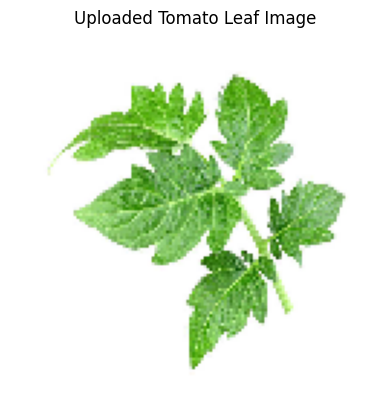

Feature extraction completed!
Feature shape: (1, 1852)


In [44]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = next(iter(uploaded.keys()))

new_image = cv2.imread(image_path)
new_image = cv2.cvtColor(new_image, cv2.COLOR_BGR2RGB)
new_image = cv2.resize(new_image, (128, 128))

plt.imshow(new_image)
plt.title("Uploaded Tomato Leaf Image")
plt.axis("off")
plt.show()

new_features = extract_features(new_image)
new_features = new_features.reshape(1, -1)

print("Feature extraction completed!")
print("Feature shape:", new_features.shape)

In [45]:
import joblib

rf_loaded = joblib.load(
    project_path + "/random_forest_model.pkl"
)

prediction = rf_loaded.predict(new_features)[0]

predicted_class = class_names[int(prediction)]

print("Predicted Disease:", predicted_class)

Predicted Disease: Tomato___Late_blight
